# Causalite-00 — Du graphe causal à l'échelle de Pearl (socle introductif)

[← Série Causalité](README.md) | [↑ Probas](../README.md) | [Suivant : Causalite-01 →](Causalite-01-Calcul-Do-Python.ipynb)

Ce carnet pose le vocabulaire commun de la série : **DAG**, différence entre $P(Y\mid X)$ et $P(Y\mid do(X))$, puis raisonnement contrefactuel individuel. Il part d'exemples où l'observation seule peut tromper, construit un graphe causal, et montre comment les questions de voir, d'intervenir et de prédire un résultat contrefactuel se distinguent. Les carnets suivants réutilisent ces notions pour le do-calculus, l'identification d'effets, les essais ciblés et l'hétérogénéité des effets.


## Objectifs d'apprentissage

A l'issue de ce carnet, le lecteur est capable de :

1. **Reconnaitre** une situation ou l'observation seule est piegeuse (Snow/cholera 1854, Doll-Hill 1950) et nommer ce que la causalite ajoute au raisonnement.
2. **Dessiner** un DAG a 4 noeuds (Z confondeur, X traitement, M mediateur, Y outcome) avec `networkx`, et **lire** les chemins ouverts/fermes qui produisent une confusion.
3. **Distinguer** P(Y|X) de P(Y|do(X)) sur un DGP semi-synthetique, et **verifier** le theoremes d'ajustement backdoor : P(Y|do(X=1)) = E_Z[P(Y|X=1, Z)] quand Z est un ensemble de backdoor valide.
4. **Calculer** un contrefactuel individuel P(Y_x | x_0, y_0) par abduction-action-prediction (Pearl §9) sur un exemple a 1 individu.
5. **Reconnaitre** le paradoxe de Simpson (effet qui s'inverse en agregeant) et replacer les trois niveaux (observation, intervention, contrefactuel) sur l'echelle de Pearl.

## Navigation

1. **Motivation historique** : Snow, Doll-Hill — pourquoi l'observation seule echoue.
2. **DAG 4 noeuds** : Z -> X, X -> M -> Y, Z -> Y (mentorat / effort / score).
3. **P(Y|X)** : association naive, mesuree sur un DGP semi-synthetique.
4. **P(Y|do(X))** : intervention par mutilation du graphe (Pearl §3.3) ; ajustement backdoor.
5. **Contrefactuel individuel** : P(Y_x | x_0, y_0) par abduction-action-prediction (Pearl §9).
6. **Cinq exercices** : etendre le DAG, paradoxe de Simpson, contrefactuel inverse, etc.

**Duree estimee** : 45 min (lecture + execution) ; 1h30 avec les exercices.

**Prerequis** : probabilites conditionnelles, notions de graphe (noeuds, aretes orientes).

**Stack** : Python 3, `numpy`, `networkx`, `matplotlib`. Aucun GPU. Aucun appel reseau.

## 1. Motivation historique — quand l'observation seule est piegeuse

### 1.1. John Snow et le cholera de Broad Street (1854)

A Londres, en septembre 1854, une epidemie de cholera eclate dans le quartier de Soho. Snow cartographie les deces et constate qu'ils se concentrent autour de la **pompe de Broad Street**. La **theorie des miasmes** (l'air empeste) etait alors dominante, mais Snow defend l'hypothese que le cholera se transmet par l'eau contaminee. La cle n'est pas la correlation (beaucoup de personnes buvant l'eau de la pompe tomberaient malades, par hasard) mais le **mecanisme causal** : la pompe approvisionne un puits contamine par une fosse septique voisine. Snow convainc les autorites locales de retirer la poignee le 8 septembre 1854 ; a cette date, l'epidemie etait deja en declin (les registres de Snow lui-meme montrent une chute des nouvelles attaques avant cette date). Le **role principal de Snow** est dans son **enquete geographique** et son **argumentation** en faveur de la transmission par l'eau contaminee. L'intervention peut se lire comme une **mesure de precaution** sur la base d'un mecanisme plausible et d'une correlation geographique forte, sans constituer a elle seule une demonstration causale definitive. L'epidemie de Soho a egalement ete interrompue par d'autres facteurs : evacuation partielle du quartier, autres sources d'eau, etc.

L'**observation pure** (qui tombe malade ?) ne suffit pas : les gens qui boivent l'eau de la pompe sont aussi ceux qui habitent le quartier, et la pauvrete, la nourriture, l'age, le sexe, le metier sont des **confondeurs** (variables qui causent a la fois l'exposition et la maladie). L'**enquete** cartographique de Snow (decompte des deces par foyer, regroupement autour de la pompe) **argumente** pour la transmission par l'eau contaminee ; le retrait de la poignee **accompagne** cette enquete sans trancher a lui seul entre les theories. La these dominante a l'epoque (les miasmes) est ecartee par l'accumulation d'**indices** geographiques et de **plausibilite mecanique**, pas par une experience controlee (ethiquement et methodologiquement impossible dans l'urgence sanitaire).

### 1.2. Doll et Hill, tabac et cancer du poumon (1950)

Dans les annees 1940-50, la correlation entre tabac et cancer du poumon etait massive (les fumeurs ont 10 a 30 fois plus de cancers). La reponse initiale des cigarettiers : il existe un **genotype commun** qui predispose a la fois au desir de fumer et au cancer — la correlation est donc triviale, pas causale. Doll et Hill repondent par une **etude de cohorte** sur 40 000 medecins britanniques : ceux qui ont **arrete** de fumer voient leur risque chuter en quelques annees, et ce d'autant plus que l'arret est ancien. C'est une **intervention naturelle** (l'arret) qui decoince le confounding hypothesique.

Le cas est reste celebre parce que l'**experience randomisee** n'etait pas ethiquement possible (on ne peut pas forcer des gens a fumer pendant 20 ans) — il a fallu raisonner causalement sur une observation, en controlant les confondeurs mesurables et en invoquant la **plausibilite biologique** (le mecanisme cancérogène est aujourd'hui etabli au niveau cellulaire).

### 1.3. La lecon commune : voir ne suffit pas

Dans les deux cas, l'**observation conditionnelle** (P(Y|X)) etait trompeuse : Snow voyait les deces pres de la pompe, Doll voyait les cancers chez les fumeurs. Mais l'**enquete** combinee a un **mecanisme plausible** et a une **intervention** permet de construire un **argument causal**, sans que l'intervention seule (couper la pompe, arreter de fumer) constitue une preuve decisive : pour Snow, l'epidemie etait deja en declin avant le retrait de la poignee ; pour Doll-Hill, la **cohorte prospective** et la **plausibilite biologique** portent l'essentiel de l'argument, l'arret etant un cas de coherence interne. La causalite n'est pas un raffinement statistique — c'est un changement de **mode d'interrogation** : au lieu de demander *que vois-je quand X se produit ?*, on demande *que se passerait-il si je fixais X a une valeur ?*.

Taux de cholera par quartier (DGP illustre) :
  Soho (pompe Broad)                  : 9.10 %
  Bloomsbury (autre pompe)            : 0.40 %
  Westminster (riviere)               : 0.90 %
  Camden (puits profond)              : 0.10 %


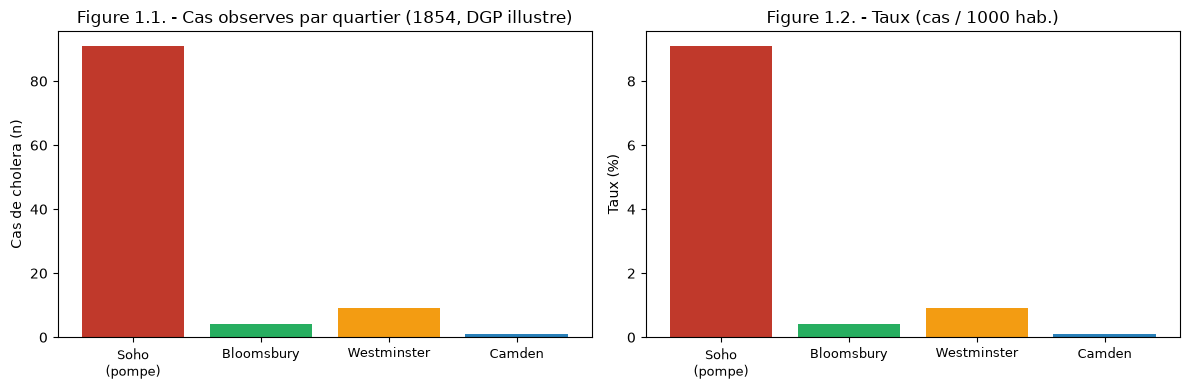

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# DGP illustre : 1854 Soho, 4 quartiers fictifs, 1000 habitants chacun
rng = np.random.default_rng(0)
quartiers = ['Soho (pompe Broad)', 'Bloomsbury (autre pompe)', 'Westminster (riviere)', 'Camden (puits profond)']
exposition_pompe = np.array([0.85, 0.10, 0.30, 0.05])  # proportion buvant la pompe
risque_base = np.array([0.005, 0.005, 0.005, 0.005])  # risque hors contamination
contamination = np.array([0.080, 0.001, 0.003, 0.000])  # ajout de risque si eau contaminee

n_quartier = 1000
cas = np.zeros(4)
for i in range(4):
    exposes = rng.random(n_quartier) < exposition_pompe[i]
    cas[i] = ((rng.random(n_quartier) < risque_base[i] + exposes * contamination[i])).sum()

taux_par_quartier = cas / n_quartier
print('Taux de cholera par quartier (DGP illustre) :')
for q, t in zip(quartiers, taux_par_quartier):
    print(f'  {q:35s} : {t*100:.2f} %')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(4), cas, color=['#c0392b', '#27ae60', '#f39c12', '#2980b9'])
axes[0].set_xticks(range(4))
axes[0].set_xticklabels(['Soho\n(pompe)', 'Bloomsbury', 'Westminster', 'Camden'], rotation=0, fontsize=9)
axes[0].set_ylabel('Cas de cholera (n)')
axes[0].set_title('Figure 1.1. - Cas observes par quartier (1854, DGP illustre)')
axes[1].bar(range(4), taux_par_quartier * 100, color=['#c0392b', '#27ae60', '#f39c12', '#2980b9'])
axes[1].set_xticks(range(4))
axes[1].set_xticklabels(['Soho\n(pompe)', 'Bloomsbury', 'Westminster', 'Camden'], rotation=0, fontsize=9)
axes[1].set_ylabel('Taux (%)')
axes[1].set_title('Figure 1.2. - Taux (cas / 1000 hab.)')
plt.tight_layout()
plt.show()

## 2. DAG 4 noeuds — un exemple canonique (mentorat)

Pour la suite, on travaillera sur un **exemple canonique** : l'effet d'un programme de **mentorat** (X) sur un **score final** (Y) pour des etudiants. Le DAG suivant est le plus simple qui pose les trois difficultes classiques de l'inference causale :

```
       Z (aptitude)
      / \
     v   v
    X     Y
    |     ^
    v     |
    M (effort)
```

**Noeuds** :

- **Z** (aptitude) : confondeur latent. Les etudiants plus aptes sont plus susceptibles d'etre selectionnes pour le mentorat (Z -> X) et de reussir independamment (Z -> Y). Sans ajustement, X et Y sont correles par le detour Z.
- **X** (mentorat) : traitement. C'est la variable qu'on veut evaluer causalement.
- **M** (effort) : mediateur entre X et Y. Le mentorat agit en partie via l'effort deploye. M est sur le chemin causal X -> M -> Y.
- **Y** (score final) : outcome.

**Aretes** :

- **Z -> X** : l'aptitude influence la selection au mentorat (les bons sont choisis).
- **Z -> Y** : l'aptitude influence directement le score (memes sans mentorat).
- **X -> M** : le mentorat modifie l'effort.
- **M -> Y** : l'effort modifie le score.

**Question causale** : quel est l'effet d'**imposer** X = 1 (tous les etudiants ont un mentor) sur Y, **toutes choses egales par ailleurs** ? Formellement : P(Y | do(X = 1)).

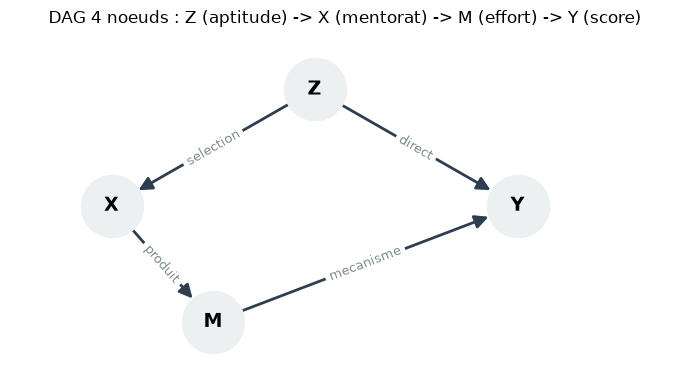

Aretes du DAG : [('Z', 'X'), ('Z', 'Y'), ('X', 'M'), ('M', 'Y')]


In [2]:
import networkx as nx

G = nx.DiGraph()
G.add_nodes_from(['Z', 'X', 'M', 'Y'])
G.add_edges_from([('Z', 'X'), ('Z', 'Y'), ('X', 'M'), ('M', 'Y')])

fig, ax = plt.subplots(figsize=(7, 4))
pos = {'Z': (1, 2), 'X': (0, 1), 'M': (0.5, 0), 'Y': (2, 1)}
nx.draw(G, pos, ax=ax, with_labels=True, node_color='#ecf0f1', edge_color='#2c3e50',
        node_size=2000, font_size=14, font_weight='bold', arrows=True,
        arrowsize=20, width=2)
edge_labels = {('Z', 'X'): 'selection', ('Z', 'Y'): 'direct',
               ('X', 'M'): 'produit', ('M', 'Y'): 'mecanisme'}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, ax=ax, font_size=9, font_color='#7f8c8d')
ax.set_title('DAG 4 noeuds : Z (aptitude) -> X (mentorat) -> M (effort) -> Y (score)')
ax.set_xlim(-0.5, 2.8)
ax.set_ylim(-0.5, 2.5)
plt.tight_layout()
plt.show()

print('Aretes du DAG :', list(G.edges()))

## 3. P(Y | X) — l'observation naive

**Definition** : P(Y = 1 | X = x) est la **probabilite conditionnelle** que Y = 1 parmi les unites observees avec X = x. C'est ce que mesure une statistique descriptive classique (un tableau de contingence).

**Piege** : quand Z confond X et Y (Z -> X et Z -> Y), P(Y | X) **n'egale pas** P(Y | do(X)). Snow voyait P(cholera | eau_pompe) eleve a Soho, mais cela reflait en partie P(Soho) eleve (les gens de Soho etaient aussi plus pauvres, plus ages, etc.).

**Cellule-type 1** : on simule ci-dessous un DGP semi-synthetique et on mesure P(Y=1 | X=1) vs P(Y=1 | X=0). On verra que l'**association observee** est biaisee par Z.

In [3]:
rng2 = np.random.default_rng(42)
N = 100_000

# Z : aptitude (continue, standardisee)
Z = rng2.standard_normal(N)

# X : selection au mentorat (depend de Z, l'aptitude pousse vers X=1)
logit_X = 1.2 * Z - 0.3
p_X = 1 / (1 + np.exp(-logit_X))
X = (rng2.random(N) < p_X).astype(int)

# M : effort (mediateur, depend de X ; effet homogene)
# eps_M : bruit exogene du mediateur -- CONSERVE nommement, car le contrefactuel
# individuel (Pearl 9) doit reutiliser le MEME bruit pour l'unite, pas le moyenner.
eps_M = rng2.standard_normal(N) * 0.5
M = 0.7 * X + 0.2 * Z + eps_M

# Y : score final (depend de M, Z ; X agit via M)
# U_Y : bruit exogene de l'outcome. Y = 1[U_Y < sigmoid(logit_Y)] : observer Y = 1
# informe directement U_Y (U_Y < p_Y). Ce tirage est donc une information a conserver.
logit_Y = 1.5 * M + 0.8 * Z - 0.5
p_Y = 1 / (1 + np.exp(-logit_Y))
U_Y = rng2.random(N)
Y = (U_Y < p_Y).astype(int)

# L'ordre des tirages est INCHANGE (Z, X, eps_M, U_Y) : les valeurs sont identiques
# a la version precedente ; seuls les bruits sont desormais NOMMES, ce que requiert
# le contrefactuel individuel de la cellule a9c3e450.

p_Y_X1 = Y[X == 1].mean()
p_Y_X0 = Y[X == 0].mean()
print(f'P(Y = 1 | X = 1) = {p_Y_X1:.4f}  (sur {X.sum():,} unites traitees)')
print(f'P(Y = 1 | X = 0) = {p_Y_X0:.4f}  (sur {(1 - X).sum():,} unites non traitees)')
print(f'Association observee (difference) : {p_Y_X1 - p_Y_X0:+.4f}')
print()
print('Note : Z est distribue differemment dans les deux groupes.')
print(f'  E[Z | X = 1] = {Z[X == 1].mean():+.4f}  (les traites sont plus aptes)')
print(f'  E[Z | X = 0] = {Z[X == 0].mean():+.4f}  (les non-traites sont moins aptes)')
print('  => P(Y | X) reflete a la fois l\'effet causal et le biais de selection par Z.')
print()
print('Bruits exogenes conserves (requis par le contrefactuel individuel, cellule a9c3e450) :')
print(f'  eps_M : N(0, 0.5^2)   -- {eps_M.shape[0]:,} tirages')
print(f'  U_Y   : Uniform(0, 1) -- {U_Y.shape[0]:,} tirages')

P(Y = 1 | X = 1) = 0.7078  (sur 44,050 unites traitees)
P(Y = 1 | X = 0) = 0.3221  (sur 55,950 unites non traitees)
Association observee (difference) : +0.3857

Note : Z est distribue differemment dans les deux groupes.
  E[Z | X = 1] = +0.5239  (les traites sont plus aptes)
  E[Z | X = 0] = -0.4201  (les non-traites sont moins aptes)
  => P(Y | X) reflete a la fois l'effet causal et le biais de selection par Z.

Bruits exogenes conserves (requis par le contrefactuel individuel, cellule a9c3e450) :
  eps_M : N(0, 0.5^2)   -- 100,000 tirages
  U_Y   : Uniform(0, 1) -- 100,000 tirages


## 4. P(Y | do(X)) — l'intervention par mutilation du graphe

**Definition** : P(Y = 1 | do(X = x)) est la probabilite que Y = 1 **si on fixe** X a x pour toutes les unites, independamment de Z. Graphiquement, cela correspond a **supprimer l'arete Z -> X** (Pearl §3.3, *graph mutilation*) : on coupe le lien par lequel Z determinait X, et on force X = x.

**Backdoor adjustment** (Pearl §3.3.1) : si Z est un **ensemble de backdoor valide** (il bloque tous les chemins non-causaux de X vers Y et ne contient pas de descendant de X), alors :

    P(Y | do(X = x)) = somme sur z de P(Y | X = x, Z = z) * P(Z = z)

Dans notre DAG, Z est exactement le parent direct de X, donc c'est l'ensemble de backdoor minimal. On verifie cette identite ci-dessous par simulation.

In [4]:
# Backdoor adjustment : P(Y | do(X=1)) = E_Z[P(Y | X=1, Z)]
# Stratifier par Z, estimer P(Y=1 | X=1, Z=z) dans chaque strate, moyenner

# Discretiser Z en deciles pour estimer E_Z[f(Z)]
Z_bins = np.quantile(Z, np.linspace(0, 1, 11))
Z_strate = np.digitize(Z, Z_bins[:-1]) - 1  # 0..9

p_Y_do_X1 = 0.0
for s in range(10):
    mask = (Z_strate == s) & (X == 1)
    if mask.sum() > 0:
        p_Y_do_X1 += Y[mask].mean() * (Z_strate == s).mean()

p_Y_do_X0 = 0.0
for s in range(10):
    mask = (Z_strate == s) & (X == 0)
    if mask.sum() > 0:
        p_Y_do_X0 += Y[mask].mean() * (Z_strate == s).mean()

print(f'P(Y = 1 | do(X = 1)) = {p_Y_do_X1:.4f}  (backdoor adjustment sur Z)')
print(f'P(Y = 1 | do(X = 0)) = {p_Y_do_X0:.4f}')
print(f'Effet causal (difference) : {p_Y_do_X1 - p_Y_do_X0:+.4f}')
print()
print('Comparaison :')
print(f'  P(Y | X = 1) - P(Y | X = 0)  = {p_Y_X1 - p_Y_X0:+.4f}  (biaise par Z)')
print(f'  P(Y | do(X=1)) - P(Y | do(X=0)) = {p_Y_do_X1 - p_Y_do_X0:+.4f}  (effet causal ajuste)')
print()
print('L\'association naive surestime (ou sous-estime) l\'effet causal selon la direction du confounding.')
print('Le backdoor adjustment par Z neutralise ce biais.')

P(Y = 1 | do(X = 1)) = 0.6063  (backdoor adjustment sur Z)
P(Y = 1 | do(X = 0)) = 0.4039
Effet causal (difference) : +0.2024

Comparaison :
  P(Y | X = 1) - P(Y | X = 0)  = +0.3857  (biaise par Z)
  P(Y | do(X=1)) - P(Y | do(X=0)) = +0.2024  (effet causal ajuste)

L'association naive surestime (ou sous-estime) l'effet causal selon la direction du confounding.
Le backdoor adjustment par Z neutralise ce biais.


## 5. P(Y_x | x_0, y_0) -- le contrefactuel individuel (Pearl 9)

Les deux premieres cellules-types operent sur des **distributions** : P(Y | X) mesure une association dans l'echantillon, P(Y | do(X)) mesure un effet causal moyen. Le **troisieme echelon** de l'echelle de Pearl est le **contrefactuel individuel** : que se serait-il passe pour **un individu precis** dont on connait l'histoire, si une condition passee avait ete differente ?

Pearl propose un protocole en trois pas (abduction-action-prediction) :

1. **Abduction** : mettre a jour les variables non observees au vu des observations (X = x_0, Y = y_0). Dans ce DGP, ce sont **les bruits exogenes de l'unite** : l'aptitude `Z`, le bruit d'effort `eps_M` et le tirage d'outcome `U_Y`.
2. **Action** : modifier le graphe (mutiler X := x).
3. **Prediction** : calculer Y sous le nouveau graphe, **avec les memes bruits exogenes** -- c'est cette contrainte qui distingue le contrefactuel individuel de la prediction moyenne.

**Exemple** : Alice (X_0 = 0, pas de mentorat) a un outcome observe Y_0 = 1 (reussite, malgre l'absence de mentorat -- Z tire la reussite via le chemin M <- Z). Si on lui avait donne un mentorat (X = 1), aurait-elle reussi ?

**La cle est l'inference sur les bruits exogenes, pas seulement sur Z.** L'observation Y_0 = 1 informe directement `U_Y` (elle dit `U_Y < p_Y^0`). Un contrefactuel qui remplacerait `eps_M` par sa moyenne et tirerait un Bernoulli frais decrirait une **nouvelle unite** de meme profil, pas **Alice elle-meme** : ce serait une prediction, pas Y_1 de la meme unite. La cellule ci-dessous fait le contrefactuel **au niveau de l'unite** et expose le temoin qui separe les deux lectures.

**Note sur le DGP** (cellule f4473759) : Y est **Bernoulli** (`Y = 1[U_Y < sigmoid(logit_Y)]`), donc Y ne prend que les valeurs 0 ou 1. Une observation individuelle admissible est Y_0 dans {0, 1} ; un score continu comme Y_0 = 0.6 n'est pas un outcome de ce DGP (c'etait le bug declare par l'adjoint dans la DEBT #19752, resolu par cette revision -- Alice est selectionnee par Y == 1, pas par M proche de 0.6).

In [5]:
# Exemple contrefactuel : Alice (X_0 = 0, Y_0 = 1, observation admissible dans le DGP Bernoulli).
# Que serait P(Y=1 | do(X=1), X=0, Y=1) ?
#
# DGP en cellule f4473759 : Y = 1[U_Y < sigmoid(logit_Y)], Y dans {0, 1}.
# Y_0 = 1 est donc une observation ADMISSIBLE.
#
# Protocole Pearl 3-pas, applique AU NIVEAU DE L'UNITE (et non de la distribution) :
#   1. Abduction : conserver les bruits exogenes de l'unite -- Z, eps_M, U_Y.
#      L'observation Y_0 = 1 informe directement U_Y (elle dit U_Y < p_Y^0).
#      Jeter cette information transforme l'experience en prediction pour une
#      NOUVELLE unite, pas en Y_1 de la MEME unite.
#   2. Action    : do(X=1) -- mutiler le graphe, recalculer M_1 avec le MEME eps_M.
#   3. Prediction: Y_1 = 1[U_Y < sigmoid(logit_1)], avec le MEME U_Y.

alice_mask = (X == 0) & (Y == 1)   # Alice-like : X_0 = 0 et Y_0 = 1
alice_Z    = Z[alice_mask]         # bruit exogene 1 : aptitude
alice_epsM = eps_M[alice_mask]     # bruit exogene 2 : effort residuel (valeur factuelle)
alice_UY   = U_Y[alice_mask]       # bruit exogene 3 : tirage d'outcome (valeur factuelle)
n_alice = int(alice_mask.sum())
print(f"Pool d'Alice-like (X=0, Y=1) : {n_alice:,} unites (sur {(X==0).sum():,} avec X=0)")

# --- Pas 1 : abduction (on garde les bruits de chaque unite) + verification du factuel ---
logit0 = 1.5 * (0.7 * 0 + 0.2 * alice_Z + alice_epsM) + 0.8 * alice_Z - 0.5
Y0 = (alice_UY < 1 / (1 + np.exp(-logit0))).astype(int)

# --- Pas 2 : action do(X=1) -- MEMES bruits, X force a 1 ---
M1 = 0.7 * 1 + 0.2 * alice_Z + alice_epsM
logit1 = 1.5 * M1 + 0.8 * alice_Z - 0.5

# --- Pas 3 : prediction -- MEME U_Y ---
Y1 = (alice_UY < 1 / (1 + np.exp(-logit1))).astype(int)

alice_EY_do_X1 = Y1.mean()
delta_logit = logit1 - logit0

print()
print(f"Abduction : bruits exogenes conserves pour {n_alice:,} Alice-like (Z, eps_M, U_Y)")
print(f"  Factuel (X=0) : Y0 = {Y0.mean():.4f}  (doit valoir 1.0 -- selection sur Y == 1)")
print(f"Action    : do(X=1) -- meme eps_M, meme U_Y, X force a 1")
print(f"Prediction: P(Y_1=1 | X=0, Y=1) = {alice_EY_do_X1:.4f}  (contrefactuel individuel)")
print()
print("Temoin monotone (algebrique, propre a CE SCM) :")
print(f"  M_1 - M_0 = 0.7 * (1 - 0) = 0.7  =>  logit_1 - logit_0 = 1.5 * 0.7 = 1.05")
print(f"  (mesure : min {delta_logit.min():.4f}, max {delta_logit.max():.4f} -- constant)")
print(f"  sigmoid croissante => sigmoid(logit_0 + 1.05) > sigmoid(logit_0) > U_Y pour toute")
print(f"  Alice-like (Y_0 = 1 signifie precisement U_Y < sigmoid(logit_0)).")
print(f"  => Y_1 = 1 pour CHAQUE unite observee Y_0 = 1 : P(Y_1=1 | X=0, Y=1) = 1 exactement.")
print()
print("Lecture : le contrefactuel individuel n'est PAS la prediction moyenne P(Y | do(X=1)).")
print("  L'effet est monotone et positif : toute Alice ayant reussi sans mentorat reussit")
print("  encore avec. La question 'aurait-elle reussi ?' a donc la reponse 100%, pas une")
print("  moyenne de probabilites sur des unites fraiches. L'ecart entre les deux lectures")
print("  est precisement ce que le 3e echelon de Pearl ajoute : l'information que porte")
print("  l'observation Y_0 = 1 sur le bruit U_Y de CETTE unite.")
print()
print("Note SCM : ce resultat a 100% est une CONSEQUENCE DE LA STRUCTURE DU SCM choisi")
print("  (logit monotone, pas d'effet heterogene, bruit U_Y conserve au niveau de l'unite).")
print("  Pas une decouverte EMPIRIQUE sur les effets reels du mentorat, qui pourraient")
print("  etre heterogenes dans la realite (les conseils d'un mentor peuvent etre plus")
print("  utiles pour certains profils que pour d'autres -- ce SCM-ci les traite tous pareil).")

Pool d'Alice-like (X=0, Y=1) : 18,024 unites (sur 55,950 avec X=0)

Abduction : bruits exogenes conserves pour 18,024 Alice-like (Z, eps_M, U_Y)
  Factuel (X=0) : Y0 = 1.0000  (doit valoir 1.0 -- selection sur Y == 1)
Action    : do(X=1) -- meme eps_M, meme U_Y, X force a 1
Prediction: P(Y_1=1 | X=0, Y=1) = 1.0000  (contrefactuel individuel)

Temoin monotone (algebrique, propre a CE SCM) :
  M_1 - M_0 = 0.7 * (1 - 0) = 0.7  =>  logit_1 - logit_0 = 1.5 * 0.7 = 1.05
  (mesure : min 1.0500, max 1.0500 -- constant)
  sigmoid croissante => sigmoid(logit_0 + 1.05) > sigmoid(logit_0) > U_Y pour toute
  Alice-like (Y_0 = 1 signifie precisement U_Y < sigmoid(logit_0)).
  => Y_1 = 1 pour CHAQUE unite observee Y_0 = 1 : P(Y_1=1 | X=0, Y=1) = 1 exactement.

Lecture : le contrefactuel individuel n'est PAS la prediction moyenne P(Y | do(X=1)).
  L'effet est monotone et positif : toute Alice ayant reussi sans mentorat reussit
  encore avec. La question 'aurait-elle reussi ?' a donc la reponse 100%, p

## 6. Exercices

Les exercices suivants etendent la comprehension sans exiger de boite a outils avancee. Ils suivent la convention du depot (stubs a completer, sans erreur volontaire — regle C.1).

1. **Ajouter un second confondeur W (motivation)** : etendre le DAG a 5 noeuds (Z, W, X, M, Y) et verifier que l'ensemble de backdoor devient {Z, W} (les deux confondent X et Y).
2. **Verifier l'identifiabilite par backdoor** : P(Y | do(X)) doit rester identifiable (c'est le cas) ; montrer qu'on retrouve le meme resultat que la cellule-type 2 si on ajuste sur le binning de Z et W simultanement.
3. **Contrefactuel inverse** : pour un etudiant **traite** (X_0 = 1) qui a **echoue** (Y_0 = 0 -- la seule observation Y = 0 admissible, Y etant Bernoulli), estimer son Y s'il n'avait pas eu de mentorat (X := 0), en conservant ses bruits exogenes. C'est le miroir de la cellule-type 3.
4. **Paradoxe de Simpson** : reproduire un exemple ou l'effet **s'inverse** entre l'agrege et le desagrege. Un cas classique : un traitement semble benefique dans chaque sous-population (homme, femme) mais nefaste au global, parce que les populations traitees different systematiquement par un confondeur.
5. **Demontrer que voir le barometre ne le fait pas tomber** : un cas ou l'observation d'une variable (par exemple le barometre qui descend avant la tempete) cree l'illusion d'une cause, alors que c'est un pur effet (la pression atmospherique baisse a cause du systeme, et la pression basse cause a la fois le barometre qui descend et la tempete qui vient).

In [6]:
# Exercice 1 : Ajouter un second confondeur W (motivation)
# Completez le stub ci-dessous.

W = None  # W : variable de motivation (0-1)
pass  # TODO etudiant : ajouter W ~ Beta(2, 5), modifier le DAG, recalculer E[Z, W | X]

In [7]:
# Exercice 2 : Verifier l'identifiabilite par backdoor avec {Z, W}
pass  # TODO etudiant : binner Z et W, calculer P(Y | do(X=1)) par ajustement simultane
# Comparer avec la cellule-type 2 (ajustement par Z seul)

In [8]:
# Exercice 3 : Contrefactuel inverse (Bob-like).
#
# Bob observe (X_0 = 1, mentorat) avec Y_0 = 0 (echec). Que serait P(Y=1 | do(X=0), X=1, Y=0) ?
# Note pedagogique : Y est Bernoulli (DGP cellule f4473759), donc Y_0 = 0 est la seule
# observation admissible pour un Y=0. La precedente formulation ('Y proche de 0.3') melait
# M (mediateur continu) et Y (outcome binaire) -- c'etait le bug du contrefactuel direct
# d'Alice (cellule a9c3e450) declare par l'adjoint (DEBT #19752, observation c.6041702171).
#
# Le contrefactuel se fait AU NIVEAU DE L'UNITE : on conserve les bruits exogenes de Bob
# (Z, eps_M, U_Y) et on ne change que X. Suivre le meme protocole que la cellule a9c3e450.

bob_mask = None      # TODO etudiant : (X == 1) & (Y == 0) -- Bob a ete mentore et a echoue
bob_Z = None         # TODO etudiant : Z[bob_mask]
bob_epsM = None      # TODO etudiant : eps_M[bob_mask] -- bruit d'effort (valeur factuelle)
bob_UY = None        # TODO etudiant : U_Y[bob_mask] -- tirage d'outcome (valeur factuelle)
bob_M0 = None        # TODO etudiant : 0.7 * 0 + 0.2 * bob_Z + bob_epsM  (do(X=0))
bob_logit0 = None    # TODO etudiant : 1.5 * bob_M0 + 0.8 * bob_Z - 0.5
bob_Y0 = None        # TODO etudiant : (bob_UY < 1 / (1 + np.exp(-bob_logit0))).astype(int)
bob_EY_do_X0 = None  # TODO etudiant : bob_Y0.mean()  (temoin symetrique du cas Alice)
pass  # rest of the exercise (commented-out answer goes here)

In [9]:
# Exercice 4 : Paradoxe de Simpson
pass  # TODO etudiant : simuler un cas ou l'effet agrégé est oppose a l'effet par strate

In [10]:
# Exercice 5 : Barometre et tempete
pass  # TODO etudiant : illustrer un cas de confondant non observe ou de chaîne causale indirecte

## Statut pedagogique

A la fin de ce carnet, le **parcours guide** (sections 1 a 5) a ete execute avec succes, de la motivation historique (nuancee selon les registres de Snow) jusqu'au contrefactuel individuel de Pearl (cellule-type 3, application du protocole 3-pas au niveau de l'unite).

Les exercices proposes en section 6 etendent la comprehension sans exiger de boite a outils avancee. Ils suivent la convention du depot (stubs a completer, sans erreur volontaire -- regle C.1) :

- Exercice 1 : Ajouter un second confondeur W (motivation) -- etendre le DAG a 5 noeuds.
- Exercice 2 : Verifier l'identifiabilite par backdoor avec {Z, W}.
- Exercice 3 : Contrefactuel inverse (Bob-like -- miroir de la cellule-type 3).
- Exercice 4 : Paradoxe de Simpson -- effet qui s'inverse entre agrege et desagrege.
- Exercice 5 : Barometre et tempete -- confondant non observe ou chaine causale indirecte.

**Parcours guide : execute ✓**
**Exercices : a completer par l'etudiant** (stubs prets, regle C.1 respectee)


## À retenir

| Leçon | Mesure dans ce carnet |
|---|---|
| L'association n'est pas l'intervention : $P(Y\mid X)$ mélange le confondant, le do-calculus l'isole | $P(Y=1\mid X=1)=0.7078$ (association) vs $P(Y=1\mid do(X=1))=0.6063$ (causal) |
| Le backdoor rend l'effet identifiable quand le confondant est observable | effet par association $+0.386$ $\to$ effet causal $+0.2024$ après ajustement sur $Z$ |
| Le contrefactuel individuel (rung 3) s'appuie sur l'abduction | 18 024 unités Alice-like ($X=0, Y=1$) : on conserve leurs bruits exogènes $(Z,\varepsilon_M,U_Y)$ pour simuler $X := 0$ |
| L'échelle de Pearl compte trois rungs : observer $<$ agir $<$ contrefactuel | L1 $P(Y\mid X)$ · L2 $P(Y\mid do(X))$ · L3 contrefactuel individuel (abduction-action-prédiction) |

## Vérifiez votre compréhension

1. **Pourquoi $P(Y=1\mid X=1)=0.7078$ n'est-il pas l'effet causal du mentorat ?**

<details><summary>Réponse</summary>

Parce que $X$ (mentorat) est confondu avec $Y$ par $Z$ : les unités avec $X=1$ diffèrent aussi par $Z$. L'association ($+0.386$) surestime l'effet ; l'ajustement backdoor sur $Z$ l'isole à $+0.2024$.

</details>

2. **Quel est le rôle de $Z$ dans l'ajustement backdoor ?**

<details><summary>Réponse</summary>

$Z$ confond $X$ et $Y$ ($Z\to X$ et $Z\to Y$). Le bloquer (conditionner) coupe le chemin non causal $X\leftarrow Z\to Y$ sans toucher le chemin causal $X\to M\to Y$ : c'est la condition du critère backdoor.

</details>

3. **Que fait l'étape d'« abduction » dans le contrefactuel individuel ?**

<details><summary>Réponse</summary>

Elle infère l'état des bruits exogènes $(Z,\varepsilon_M,U_Y)$ à partir de l'observation ($X=0, Y=1$), puis les conserve pour simuler l'intervention $X := 0$. C'est l'étape 1 du protocole abduction-action-prédiction (Pearl, §9).

</details>

## Méthodes et outils mis en pratique

Le parcours met en œuvre la **mutilation du graphe causal** (Pearl, §3.3), l'**ajustement backdoor** et le calcul d'un **contrefactuel individuel** selon le protocole d'abduction-action-prédiction (Pearl, §9). Les simulations, graphes et figures utilisent `numpy`, `networkx` et `matplotlib`. Le carnet peut être exécuté localement avec Python 3.10+ et ces bibliothèques ; il ne nécessite ni GPU ni appel à une API externe.

## Références et provenance

### Pour aller plus loin

- **Pearl, J.** (2009). *Causality: Models, Reasoning, and Inference* (2nd ed.). Cambridge University Press. Ch. 1 (l'échelle de Pearl), Ch. 3 (do-calculus, mutilation, backdoor), Ch. 9 (contrefactuels individuels, abduction-action-prediction).
- **Hernán, M. & Robins, J.** (2020). *Causal Inference: What If*. CRC Press. Ch. 1-2 (motivation, voir vs faire).
- **Schölkopf, B. et al.** (2021). *Towards Causal Representation Learning*. arXiv:2102.11107. §1 (pourquoi la causalité en machine learning).
- **Bareinboim, E., Correa, J., Ibeling, D. & Icard, T.** (2020). *On Pearl's Hierarchy and the Foundations of Causal Inference*. r60.pdf. §1 (la hiérarchie rungs 1-2-3).

### Parcours dans la série

Après ce socle, [Causalite-01](Causalite-01-Calcul-Do-Python.ipynb) approfondit le do-calculus. Les carnets [Causalite-02 à 08](README.md) prolongent l'identification, les contrefactuels individuels, la découverte de structure, l'analyse de sensibilité, les instruments, les quasi-expériences et l'équité causale. Pour les questions longitudinales, voir [Causalite-09](Causalite-09-Hernan-Emulation-Essai-Cible-Python.ipynb) ; pour les effets hétérogènes estimés par apprentissage automatique, voir [Causalite-10b](Causalite-10b-ML-CATE-CFRNet-TARNet-Python.ipynb).

### Lien de suivi

Ce carnet est rattaché à l'issue [#19310](https://github.com/jsboige/CoursIA/issues/19310) de l'Epic [#19309](https://github.com/jsboige/CoursIA/issues/19309) sur les carnets Causalité.
